# 16c — Why market regimes? Evidence before fitting an HMM

Before building a hidden Markov model (HMM) and adding its state probabilities as features, this notebook checks whether the idea has support in the data. An HMM feature can only help the forecast if all of these hold:

| # | Question | Why it matters |
|---|---|---|
| Q1 | Are there **slow, persistent** market conditions? | An HMM models states that last for weeks. If conditions change randomly every day, there are no regimes to find. |
| Q2 | Do they look like **distinct states** rather than one smooth distribution? | A few discrete states describe the data well only if the data clusters. |
| Q3 | Does **auction volume behave differently** across those conditions? | The regimes must matter for the target. |
| Q4 | Do the **feature–target relationships shift over time** along with those conditions? | Trees can learn level differences from existing features. Regimes add most where *relationships* change. |
| Q5 | Does the **current best model leave errors that depend on market condition**? | If 16a's tuned LightGBM already handles this, a regime feature has nothing left to explain. |
| Q6 | Which candidate inputs carry **distinct information**? | Redundant inputs add parameters and make the HMM unstable. |

**Inputs.** Six market-wide daily inputs, built in `regime_utils.py`. Each is computed from data up to the close of day d and then shifted, so the value attached to prediction date t uses information only up to t−1. Rolling baselines exclude month-end, expiry and early-close days, so the calendar, which the model already knows, doesn't leak into the "regimes".

**Leakage-free comparisons.** Tercile cut points ("low / mid / high") are fitted on 2015–2021 only. Model-error checks use the 2022–2025 out-of-time predictions from Notebook 16a.

In [1]:
from pathlib import Path
import json
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.mixture import GaussianMixture

import regime_utils as ru

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110})

cwd = Path.cwd().resolve()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists())
PANEL = ROOT / "outputs/eda/05_feature_engineering/enriched_daily_panel.parquet"
PRED_16A = ROOT / "outputs/eda/16a_lightgbm_improvements/predictions"
OUT = ROOT / "outputs/eda/16c_regime_motivation"
OUT.mkdir(parents=True, exist_ok=True)
for required in [PANEL, PRED_16A]:
    if not required.exists():
        raise FileNotFoundError(f"{required} missing: run Notebooks 05 and 16a first.")

con = duckdb.connect()
con.execute("PRAGMA threads=4")
sql = lambda q: con.execute(q).df()

inputs = ru.build_regime_inputs(con, ROOT)
X = inputs.loc["2015-01-01":, ru.INPUTS]
print(f"{len(inputs):,} trading days; analysis window 2015–2025: {len(X):,} days")
display(X.describe().T)
display(X.isna().mean().rename("share_missing").to_frame().T)

3,772 trading days; analysis window 2015–2025: 2,766 days


,count,mean,std,min,25%,50%,75%,max
activity,"2,766.0000",0.0107,0.1413,-0.5438,-0.0722,0.0027,0.0795,0.8322
realized_vol,"2,766.0000",-2.0896,0.4839,-3.4254,-2.4201,-2.1450,-1.7948,-0.0106
auction_share_dev,"2,617.0000",0.0392,0.1256,-0.4033,-0.0350,0.0372,0.1175,0.3661
dispersion,"2,766.0000",-3.6194,0.2148,-4.0532,-3.7766,-3.6230,-3.4905,-2.5797
fear_premium,"2,664.0000",1.0599,0.3666,-0.3438,0.8185,1.0915,1.3156,2.2192
drawdown,"2,766.0000",-0.0275,0.0381,-0.3534,-0.0378,-0.0133,-0.0024,0.0000


,activity,realized_vol,auction_share_dev,dispersion,fear_premium,drawdown
share_missing,0.0000,0.0000,0.0539,0.0000,0.0369,0.0000


## Q1 — Are market conditions slow and persistent?

The six inputs over time, with well-known stress episodes shaded in grey.

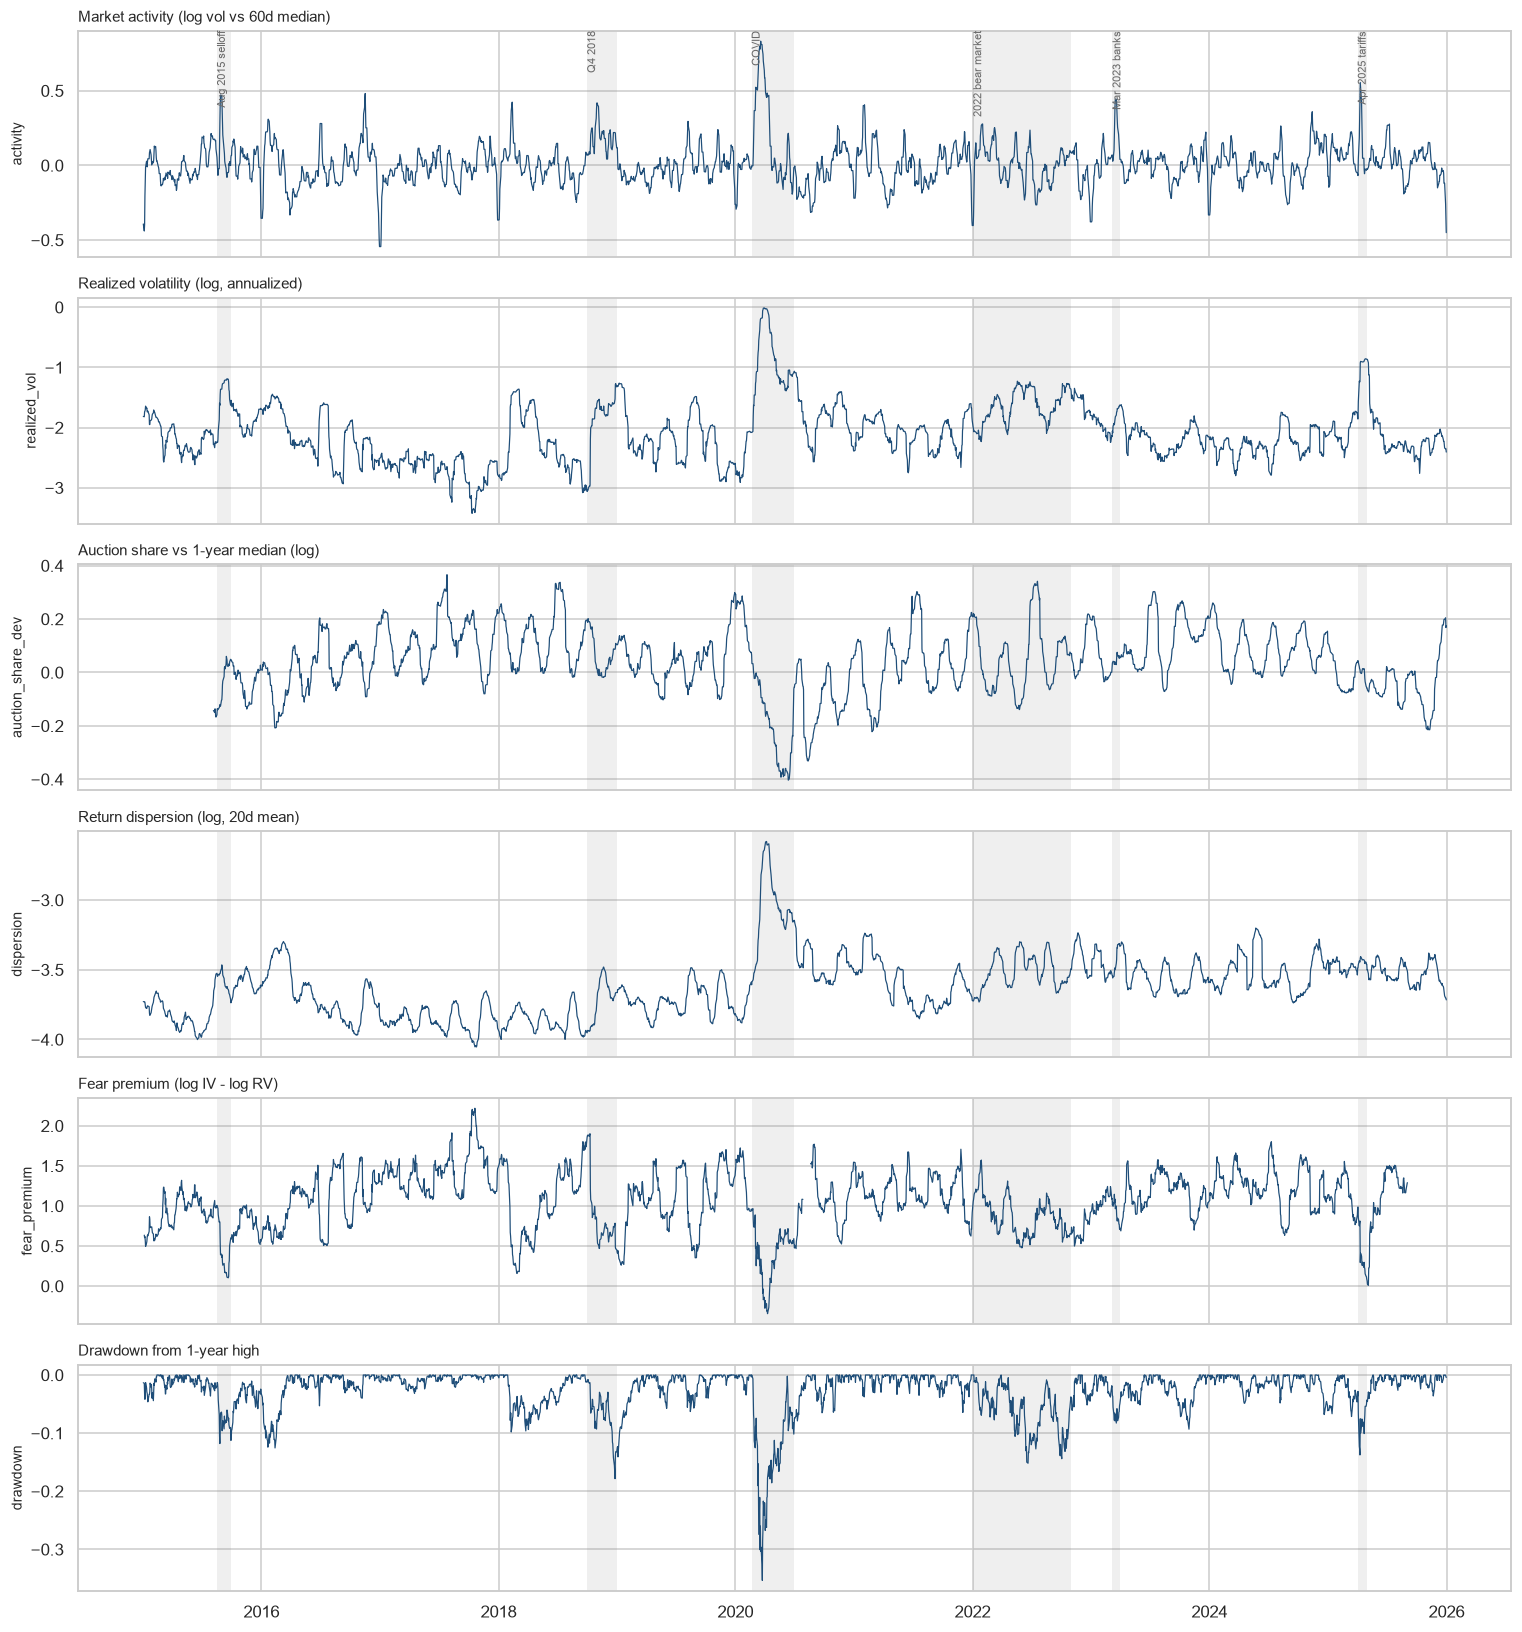

In [2]:
fig, axes = plt.subplots(len(ru.INPUTS), 1, figsize=(14, 15), sharex=True)
for ax, col in zip(axes, ru.INPUTS):
    ax.plot(X.index, X[col], lw=0.8, color="#1f4e79")
    ru.shade_episodes(ax)
    ax.set_ylabel(col, fontsize=9)
    ax.set_title(ru.LABELS[col], fontsize=10, loc="left")
for start, end, label in ru.EPISODES:
    axes[0].annotate(label, (pd.Timestamp(start), axes[0].get_ylim()[1]), fontsize=7, va="top", rotation=90, color="dimgrey")
plt.tight_layout()
plt.savefig(OUT / "q1_inputs_over_time.png", bbox_inches="tight")
plt.show()

**Persistence.** How strongly does each input correlate with its own value 1–60 days later (autocorrelation)? For comparison, the same is shown for the market-wide average error of the best current model (16a tuned LightGBM, 2022–2025).

lag_days,1,2,5,10,20,40,60
activity,0.9653,0.8959,0.6040,0.3496,0.1677,-0.0797,-0.0211
realized_vol,0.9887,0.9747,0.9186,0.8029,0.5526,0.3764,0.1966
auction_share_dev,0.9908,0.9768,0.9146,0.7476,0.3153,0.1257,0.5752
dispersion,0.9951,0.9869,0.9480,0.8517,0.6564,0.5376,0.5224
fear_premium,0.9788,0.9551,0.8637,0.6851,0.3391,0.2270,0.0765
drawdown,0.9693,0.9436,0.8637,0.7483,0.5247,0.2493,0.0931
model_daily_mean_error,0.0242,0.0439,-0.0014,0.0053,-0.0046,0.0192,0.0292


,P(same tercile next day),mean spell length (days)
activity,0.8485,6.5929
realized_vol,0.9321,14.6758
auction_share_dev,0.9365,15.6707
dispersion,0.9566,22.9085
fear_premium,0.9091,10.9180
drawdown,0.7976,4.9351


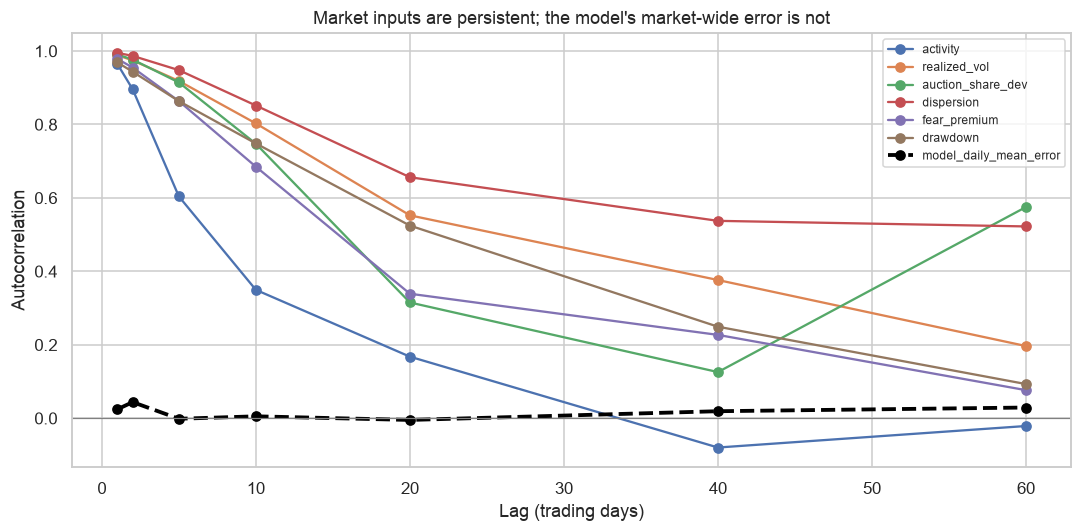

In [3]:
daily_err = sql(f"""
    SELECT date, avg(log1p_auction_volume - ln(1 + lgbm_61_ratios_large_tuned)) AS model_daily_mean_error
    FROM read_parquet('{PRED_16A}/*.parquet') GROUP BY date ORDER BY date
""").set_index("date")["model_daily_mean_error"]

lags = [1, 2, 5, 10, 20, 40, 60]
acf = pd.DataFrame({col: [X[col].dropna().autocorr(k) for k in lags] for col in ru.INPUTS}, index=lags)
acf["model_daily_mean_error"] = [daily_err.autocorr(k) for k in lags]
acf.index.name = "lag_days"
acf.to_csv(OUT / "q1_autocorrelation.csv")
display(acf.T)

# Regime "stickiness": probability of staying in the same tercile from one day to the next.
edges = ru.tercile_edges(inputs, ru.INPUTS)
terc = ru.assign_terciles(inputs, edges)
stay = {col: (terc[col] == terc[col].shift(1))[terc[col].notna() & terc[col].shift(1).notna()].mean() for col in ru.INPUTS}
spell = {}
for col in ru.INPUTS:
    s = terc[col].dropna().astype(str)
    runs = (s != s.shift()).cumsum()
    spell[col] = s.groupby(runs).size().mean()
sticky = pd.DataFrame({"P(same tercile next day)": stay, "mean spell length (days)": spell})
sticky.to_csv(OUT / "q1_tercile_stickiness.csv")
display(sticky)

fig, ax = plt.subplots(figsize=(10, 5))
for col in acf.columns:
    style = dict(lw=2.5, color="black", ls="--") if col == "model_daily_mean_error" else dict(lw=1.5)
    ax.plot(acf.index, acf[col], marker="o", label=col, **style)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="Lag (trading days)", ylabel="Autocorrelation", title="Market inputs are persistent; the model's market-wide error is not")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "q1_persistence.png", bbox_inches="tight")
plt.show()

**Reading Q1.** Yes, market conditions are slow-moving.

- Every input still has a correlation of about 0.6–0.99 with itself 5 days later.
- Once in a tercile, an input typically stays there for 5–23 trading days. That's the "sticky state" behavior an HMM's transition matrix represents.
- The stress episodes stand out clearly in volatility, dispersion and drawdown.
- **In contrast, the best model's market-wide daily error has essentially no persistence** (about 0.02 at lag 1). Conditions persist, but the part of the error that hits all stocks on the same day doesn't. That's the first warning sign.
- The auction-share input shows a bump at lag 60, about one quarter, which suggests a quarterly cycle that the regular-day filter doesn't fully remove.

## Q2 — Distinct states or one smooth distribution?

First, each input's distribution against a single normal curve. Fat tails and skew suggest a mixture of conditions. Then a **static** Gaussian mixture on the core three inputs, with BIC for 1–6 components. It ignores time order, so it is only a preview: the HMM adds the persistence shown in Q1.

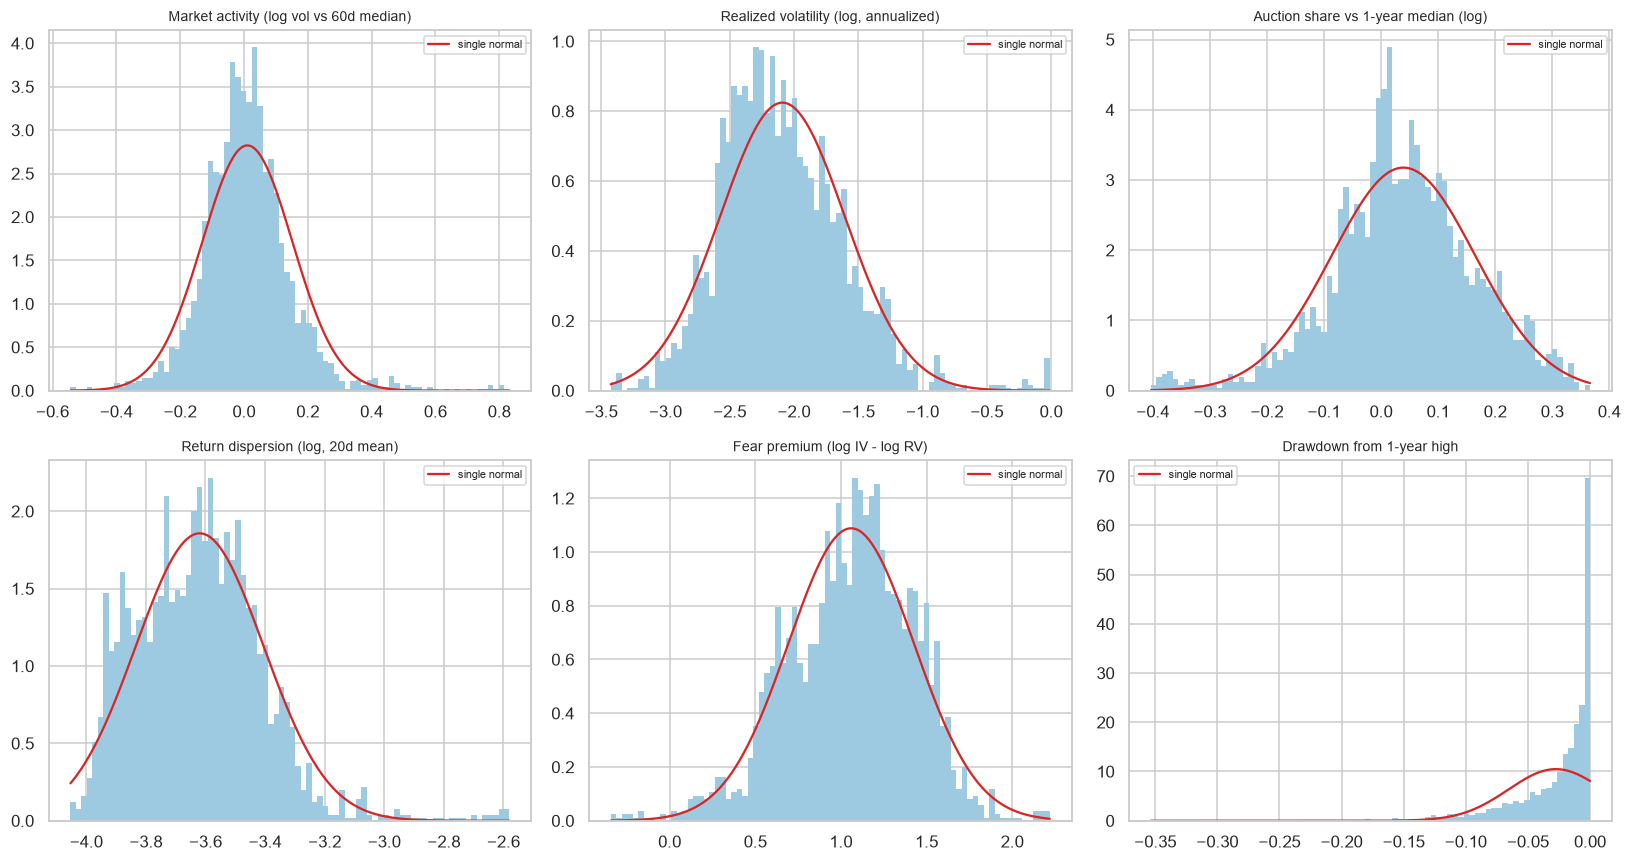

,skew,excess_kurtosis
input,,
activity,0.9631,4.5868
realized_vol,0.7363,1.6267
auction_share_dev,-0.3099,0.6644
dispersion,0.8693,2.2502
fear_premium,-0.3298,0.3399
drawdown,-2.8294,12.2003


,bic,log_likelihood,bic_change_vs_previous
components,,,
1,"21,724.3487","-10,826.7603",NaN
2,"21,099.7595","-10,475.1168",-624.5892
3,"20,892.3774","-10,332.0768",-207.3821
4,"20,946.6878","-10,319.8831",54.3105
5,"20,886.3025","-10,250.3415",-60.3853
6,"20,897.0730","-10,216.3779",10.7705


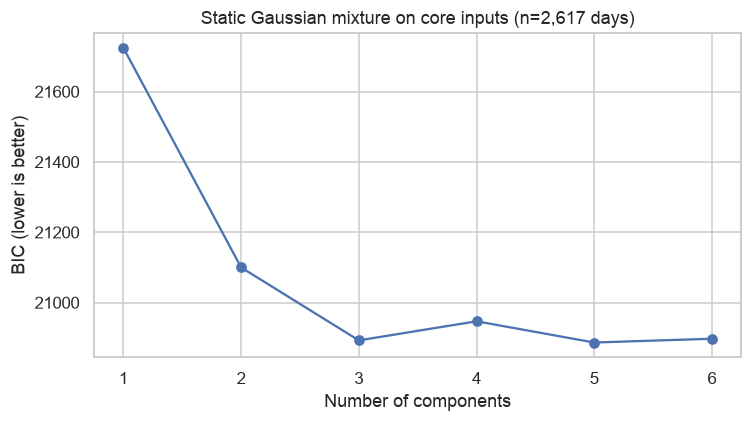

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
shape_rows = []
for ax, col in zip(axes.ravel(), ru.INPUTS):
    v = X[col].dropna()
    ax.hist(v, bins=80, density=True, color="#9ecae1", edgecolor="none")
    grid = np.linspace(v.min(), v.max(), 300)
    ax.plot(grid, stats.norm.pdf(grid, v.mean(), v.std()), color="#d62728", lw=1.5, label="single normal")
    ax.set_title(ru.LABELS[col], fontsize=9)
    ax.legend(fontsize=7)
    shape_rows.append({"input": col, "skew": stats.skew(v), "excess_kurtosis": stats.kurtosis(v)})
plt.tight_layout()
plt.savefig(OUT / "q2_distributions.png", bbox_inches="tight")
plt.show()
shape = pd.DataFrame(shape_rows).set_index("input")
display(shape)

core = X[ru.CORE_INPUTS].dropna()
z = (core - core.mean()) / core.std()
bic_rows = []
for k in range(1, 7):
    gm = GaussianMixture(k, covariance_type="full", n_init=10, random_state=0).fit(z)
    bic_rows.append({"components": k, "bic": gm.bic(z), "log_likelihood": gm.score(z) * len(z)})
bic = pd.DataFrame(bic_rows).set_index("components")
bic["bic_change_vs_previous"] = bic.bic.diff()
bic.to_csv(OUT / "q2_gaussian_mixture_bic.csv")
display(bic)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bic.index, bic.bic, marker="o")
ax.set(xlabel="Number of components", ylabel="BIC (lower is better)",
       title=f"Static Gaussian mixture on core inputs (n={len(z):,} days)")
plt.tight_layout()
plt.savefig(OUT / "q2_mixture_bic.png", bbox_inches="tight")
plt.show()

**Reading Q2.**

- Several inputs are skewed or fat-tailed. Volatility and dispersion have long right tails, and drawdown a long left tail, so one normal curve describes them poorly.
- On the core three inputs, BIC falls sharply from 1 to 2 to 3 components and is roughly flat after that. That suggests about **three states**, likely calm, normal and stressed.
- The 5-component minimum is only marginally lower than 3. That's the usual BIC behavior on fat-tailed data, where extra components absorb outliers, which is why the HMM step should look for where the BIC curve flattens rather than just its minimum.

## Q3 — Does auction volume behave differently across market conditions?

The target here is the model's own residual target: r = log(auction volume) − log(20-day median auction volume), i.e. how far today's auction lands from the stock's recent normal. Rows are all eligible stock-days on **regular** (non-event) days, grouped by the prior-day tercile of each input. Besides the average level, this checks whether the *relationships* change: the slope of r on yesterday's spike ratio (ln of lag-1 ÷ 20-day median) and on yesterday's abnormal daily volume.

,input,tercile,stock_days,mean_r,sd_r,slope_on_spike_ratio,slope_on_abnormal_volume
0,activity,low,946488,-0.0256,0.5969,0.2076,0.2531
2,activity,mid,1043000,0.0420,0.6077,0.2057,0.2528
1,activity,high,1132462,0.0535,0.5608,0.1974,0.2543
1,auction_share_dev,low,910424,0.0375,0.5607,0.2118,0.2469
0,auction_share_dev,mid,1024637,0.0500,0.5721,0.2126,0.2572
2,auction_share_dev,high,1007929,-0.0076,0.6114,0.2036,0.2671
1,dispersion,low,673473,0.0297,0.6780,0.1769,0.2544
0,dispersion,mid,848741,0.0220,0.6059,0.1986,0.2592
2,dispersion,high,1599736,0.0260,0.5368,0.2282,0.2583
1,drawdown,low,1141432,0.0358,0.5777,0.2107,0.2624


,tercile,quarterly_expiry_lift,expiry_days
1,low,1.9918,12
2,mid,1.9079,18
0,high,2.0166,14


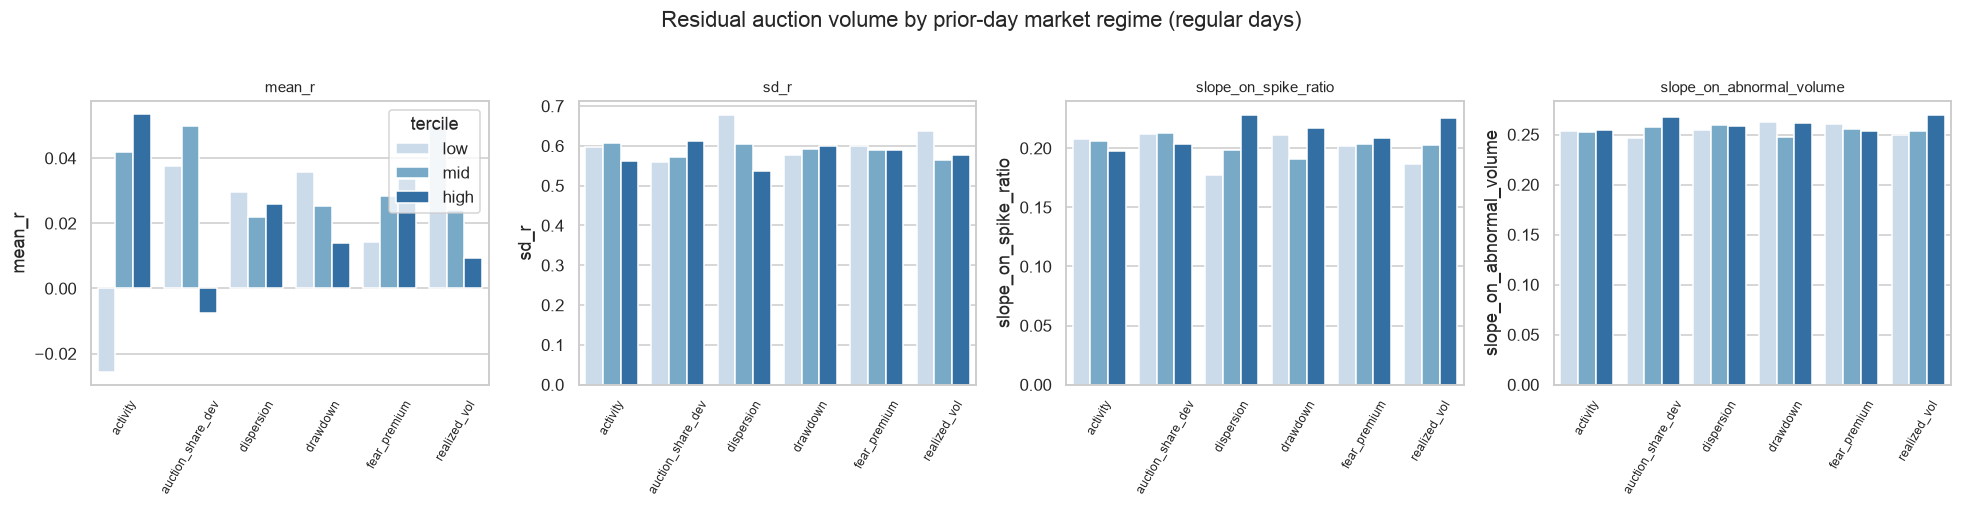

In [5]:
regime_table = inputs[ru.INPUTS + ["event_day"]].copy()
for col in ru.INPUTS:
    regime_table[f"{col}_tercile"] = terc[col].astype(str)
regime_table = regime_table.reset_index()
con.register("regime", regime_table)

panel_cte = f"""
    panel AS (
        SELECT p.date, p.quarterly_options_expiry,
               p.log1p_auction_volume - ln(1 + p.median20_auction_volume) AS r,
               ln((p.lag1_auction_volume + 1) / (p.median20_auction_volume + 1)) AS spike_ratio,
               ln(p.abnormal_volume_lag1) AS abnormal_daily_volume
        FROM read_parquet('{PANEL}') p
        WHERE p.eligible_target AND p.median20_auction_volume IS NOT NULL
          AND p.lag1_auction_volume IS NOT NULL AND p.abnormal_volume_lag1 > 0
    )"""

q3_rows = []
for col in ru.INPUTS:
    q3_rows.append(sql(f"""
        WITH {panel_cte}
        SELECT '{col}' AS input, g."{col}_tercile" AS tercile, count(*) AS stock_days,
               avg(r) AS mean_r, stddev(r) AS sd_r,
               regr_slope(r, spike_ratio) AS slope_on_spike_ratio,
               regr_slope(r, abnormal_daily_volume) AS slope_on_abnormal_volume
        FROM panel JOIN regime g USING (date)
        WHERE NOT g.event_day AND g."{col}_tercile" IN ('low', 'mid', 'high')
        GROUP BY 1, 2
    """))
q3 = pd.concat(q3_rows)
q3["tercile"] = pd.Categorical(q3.tercile, ["low", "mid", "high"])
q3 = q3.sort_values(["input", "tercile"])
q3.to_csv(OUT / "q3_target_by_regime.csv", index=False)
display(q3)

# Event amplitude by regime: quarterly-expiry lift (mean r on expiry days minus regular days).
lift = sql(f"""
    WITH {panel_cte}
    SELECT g.realized_vol_tercile AS tercile,
           avg(r) FILTER (WHERE quarterly_options_expiry) - avg(r) FILTER (WHERE NOT g.event_day) AS quarterly_expiry_lift,
           count(DISTINCT date) FILTER (WHERE quarterly_options_expiry) AS expiry_days
    FROM panel JOIN regime g USING (date)
    WHERE g.realized_vol_tercile IN ('low', 'mid', 'high') GROUP BY 1
""")
lift["tercile"] = pd.Categorical(lift.tercile, ["low", "mid", "high"])
display(lift.sort_values("tercile"))

metrics = ["mean_r", "sd_r", "slope_on_spike_ratio", "slope_on_abnormal_volume"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, metric in zip(axes, metrics):
    sns.barplot(data=q3, x="input", y=metric, hue="tercile", ax=ax, palette="Blues")
    ax.set_title(metric, fontsize=10)
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.set_xlabel("")
    if ax is not axes[0]:
        ax.get_legend().remove()
plt.suptitle("Residual auction volume by prior-day market regime (regular days)", y=1.02)
plt.tight_layout()
plt.savefig(OUT / "q3_target_by_regime.png", bbox_inches="tight")
plt.show()

## Q4 — Do relationships shift over time with market conditions?

Each quarter, the slope of r on yesterday's spike ratio (regular days only) is compared with that quarter's average market inputs. If the slope moves with the inputs, a regime feature gives trees a direct handle on *when* relationships change.

,slope_on_spike_ratio,slope_on_abnormal_volume,mean_r,sd_r
quarterly mean of input,,,,
activity,0.0988,0.1922,0.2733,-0.2273
realized_vol,0.2004,0.0936,-0.0796,-0.2266
auction_share_dev,-0.0988,-0.1583,0.1516,0.0848
dispersion,0.5163,0.1863,-0.1442,-0.6985
fear_premium,0.0886,0.0168,0.0417,-0.0375
drawdown,-0.0390,-0.0858,0.0200,0.1219


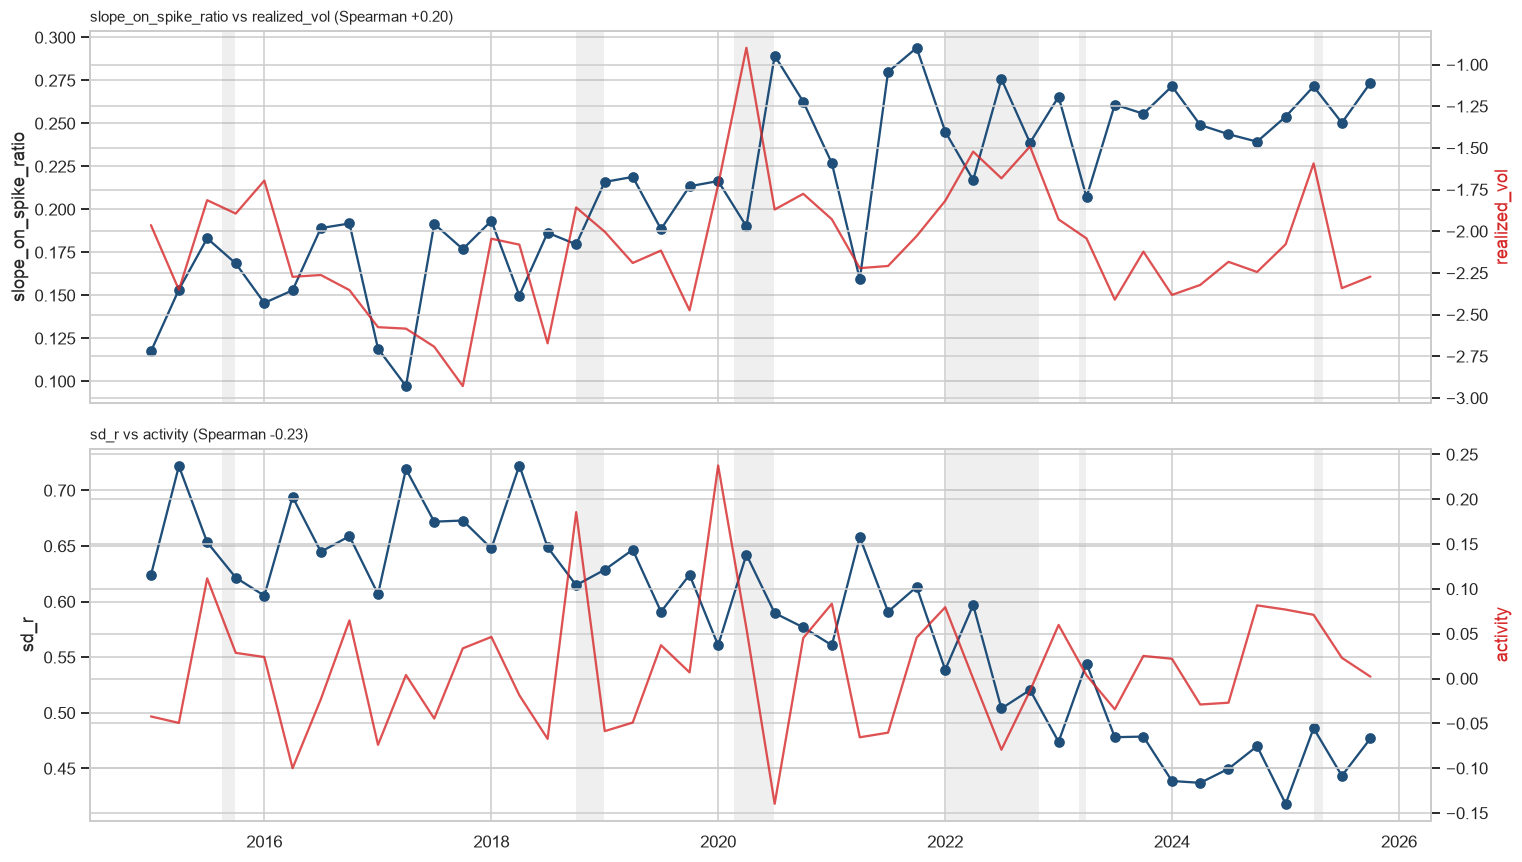

In [6]:
quarterly = sql(f"""
    WITH {panel_cte}
    SELECT date_trunc('quarter', date) AS quarter,
           regr_slope(r, spike_ratio) AS slope_on_spike_ratio,
           regr_slope(r, abnormal_daily_volume) AS slope_on_abnormal_volume,
           avg(r) AS mean_r, stddev(r) AS sd_r
    FROM panel JOIN regime g USING (date)
    WHERE NOT g.event_day GROUP BY 1 ORDER BY 1
""").set_index("quarter")
quarter_inputs = X.groupby(X.index.to_period("Q").to_timestamp()).mean()
quarterly = quarterly.join(quarter_inputs)
quarterly.to_csv(OUT / "q4_quarterly_relationships.csv")

link = pd.DataFrame({
    metric: {col: quarterly[[metric, col]].corr(method="spearman").iloc[0, 1] for col in ru.INPUTS}
    for metric in ["slope_on_spike_ratio", "slope_on_abnormal_volume", "mean_r", "sd_r"]
})
link.index.name = "quarterly mean of input"
link.to_csv(OUT / "q4_relationship_vs_inputs_spearman.csv")
display(link)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, metric, partner in [(axes[0], "slope_on_spike_ratio", "realized_vol"), (axes[1], "sd_r", "activity")]:
    ax.plot(quarterly.index, quarterly[metric], marker="o", color="#1f4e79", label=metric)
    ax.set_ylabel(metric)
    ru.shade_episodes(ax)
    twin = ax.twinx()
    twin.plot(quarterly.index, quarterly[partner], color="#d62728", lw=1.5, alpha=0.8, label=f"{partner} (quarterly mean)")
    twin.set_ylabel(partner, color="#d62728")
    ax.set_title(f"{metric} vs {partner} (Spearman {link.loc[partner, metric]:+.2f})", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(OUT / "q4_relationships_over_time.png", bbox_inches="tight")
plt.show()

**Robustness: shared trends.** Both the spike-ratio slope and some inputs drift over the decade. Two series that both trend correlate even if they are unrelated. Repeating the check on quarter-to-quarter *changes* removes the shared trend.

In [7]:
changes = quarterly.diff()
link_changes = pd.DataFrame({
    metric: {col: changes[[metric, col]].corr(method="spearman").iloc[0, 1] for col in ru.INPUTS}
    for metric in ["slope_on_spike_ratio", "slope_on_abnormal_volume", "mean_r", "sd_r"]
})
link_changes.index.name = "quarterly change of input"
link_changes.to_csv(OUT / "q4_relationship_vs_inputs_spearman_changes.csv")
display(pd.concat({"levels": link["slope_on_spike_ratio"], "changes": link_changes["slope_on_spike_ratio"]}, axis=1)
        .rename_axis("input").add_prefix("slope_on_spike_ratio: "))
display(link_changes)

,slope_on_spike_ratio: levels,slope_on_spike_ratio: changes
input,,
activity,0.0988,-0.0299
realized_vol,0.2004,-0.2457
auction_share_dev,-0.0988,0.1787
dispersion,0.5163,-0.2433
fear_premium,0.0886,0.2315
drawdown,-0.0390,0.2394


,slope_on_spike_ratio,slope_on_abnormal_volume,mean_r,sd_r
quarterly change of input,,,,
activity,-0.0299,0.0492,0.3337,-0.1666
realized_vol,-0.2457,-0.1361,0.0912,0.0133
auction_share_dev,0.1787,0.2108,-0.0758,-0.1371
dispersion,-0.2433,-0.1640,0.1342,-0.1134
fear_premium,0.2315,0.0944,-0.0416,-0.0808
drawdown,0.2394,0.0581,0.0245,0.0399


**Reading Q3–Q4.**

- **Levels differ by regime.** After quiet or low-volatility days, auctions land above their 20-day median more often, and after high-activity days too. The gaps between terciles are about 0.04–0.08 in log terms.
- **Relationships shift a little.** The slope on yesterday's spike ratio ranges from about 0.18 to 0.23 across volatility and dispersion terciles, roughly ±12% around its average.
- **The big movement over time is a slow trend, not regimes.** The spike-ratio slope roughly doubles between 2015 and 2025, and the spread of r shrinks. Once shared trends are removed, the strongest link (dispersion, +0.52 on levels) changes sign. Rolling 5-year training windows already adapt to slow drift like this.

## Q5 — Does the current best model leave condition-dependent errors?

Error = log(actual) − log(predicted) for Notebook 16a's tuned LightGBM and for the frozen ridge, 2022–2025, by prior-day tercile of each input. A regime feature can only help where the error **mean (bias)** or **spread** differs systematically between terciles.

,input,tercile,stock_days,bias_lgbm,rmse_lgbm,bias_ridge,rmse_ridge
1,activity,low,315970,0.0127,0.4651,0.0186,0.4789
0,activity,mid,430019,0.0141,0.4563,0.0232,0.4851
2,activity,high,525389,0.0201,0.4488,0.0169,0.4757
2,auction_share_dev,low,349085,-0.0043,0.4495,0.0024,0.4671
0,auction_share_dev,mid,464194,0.0230,0.4567,0.0256,0.4689
1,auction_share_dev,high,458099,0.0250,0.4586,0.0263,0.4996
0,dispersion,mid,208168,0.0180,0.4541,0.0201,0.4701
1,dispersion,high,1063210,0.0159,0.4557,0.0193,0.4816
1,drawdown,low,533126,0.0226,0.4669,0.0182,0.4886
0,drawdown,mid,427389,0.0218,0.4514,0.0248,0.4807


,bias_range_lgbm,rmse_range_lgbm,bias_range_ridge
input,,,
activity,0.0074,0.0163,0.0063
auction_share_dev,0.0293,0.0091,0.0239
dispersion,0.0021,0.0016,0.0008
drawdown,0.0249,0.0263,0.0105
fear_premium,0.0327,0.0449,0.0401
realized_vol,0.0327,0.0304,0.0487


,Spearman with model's market-wide daily error
activity,0.0268
realized_vol,-0.0810
auction_share_dev,0.1003
dispersion,-0.1298
fear_premium,0.1434
drawdown,-0.0664


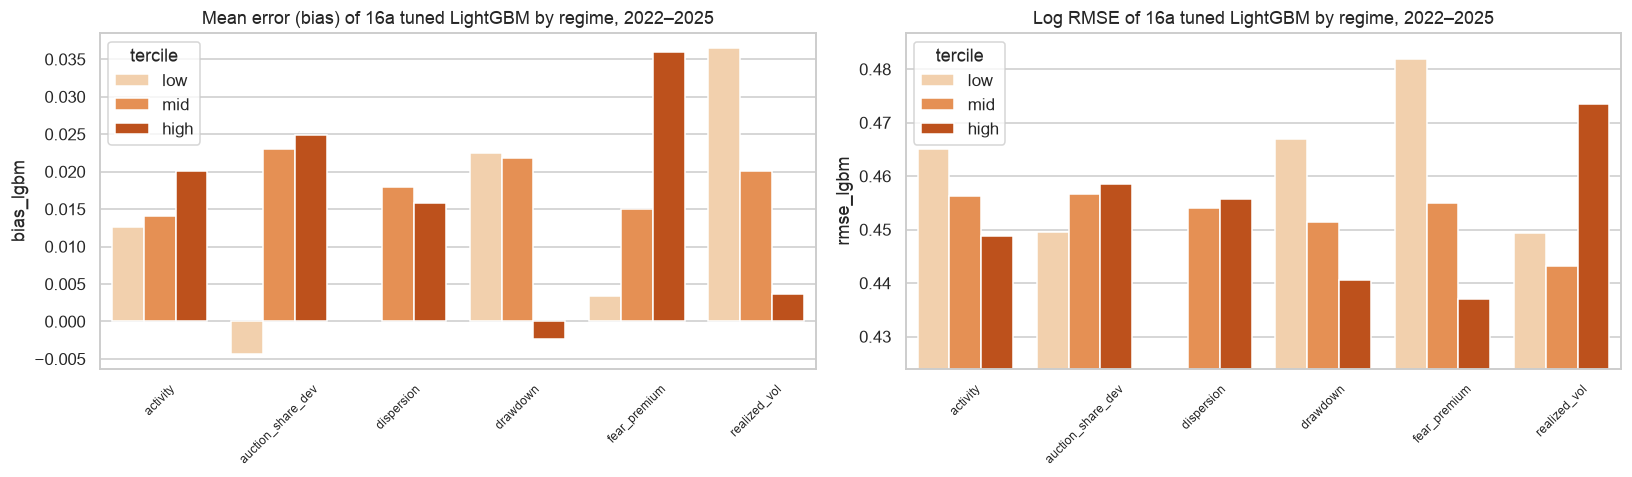

In [8]:
q5_rows = []
for col in ru.INPUTS:
    q5_rows.append(sql(f"""
        WITH e AS (
            SELECT date, log1p_auction_volume - ln(1 + lgbm_61_ratios_large_tuned) AS err_lgbm,
                   log1p_auction_volume - ln(1 + frozen_prediction) AS err_ridge
            FROM read_parquet('{PRED_16A}/*.parquet')
        )
        SELECT '{col}' AS input, g."{col}_tercile" AS tercile, count(*) AS stock_days,
               avg(err_lgbm) AS bias_lgbm, sqrt(avg(err_lgbm * err_lgbm)) AS rmse_lgbm,
               avg(err_ridge) AS bias_ridge, sqrt(avg(err_ridge * err_ridge)) AS rmse_ridge
        FROM e JOIN regime g USING (date)
        WHERE g."{col}_tercile" IN ('low', 'mid', 'high') GROUP BY 1, 2
    """))
q5 = pd.concat(q5_rows)
q5["tercile"] = pd.Categorical(q5.tercile, ["low", "mid", "high"])
q5 = q5.sort_values(["input", "tercile"])
q5.to_csv(OUT / "q5_model_error_by_regime.csv", index=False)
display(q5)

spread = q5.groupby("input").agg(
    bias_range_lgbm=("bias_lgbm", lambda s: s.max() - s.min()),
    rmse_range_lgbm=("rmse_lgbm", lambda s: s.max() - s.min()),
    bias_range_ridge=("bias_ridge", lambda s: s.max() - s.min()),
)
display(spread)

daily = daily_err.to_frame().join(X)
corr_err = daily.corr(method="spearman")["model_daily_mean_error"].drop("model_daily_mean_error")
display(corr_err.rename("Spearman with model's market-wide daily error").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric in zip(axes, ["bias_lgbm", "rmse_lgbm"]):
    sns.barplot(data=q5, x="input", y=metric, hue="tercile", ax=ax, palette="Oranges")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.set_xlabel("")
ax.set_ylim(q5.rmse_lgbm.min() * 0.97, q5.rmse_lgbm.max() * 1.01)
axes[0].set_title("Mean error (bias) of 16a tuned LightGBM by regime, 2022–2025")
axes[1].set_title("Log RMSE of 16a tuned LightGBM by regime, 2022–2025")
plt.tight_layout()
plt.savefig(OUT / "q5_model_error_by_regime.png", bbox_inches="tight")
plt.show()

**Upper bound on the point-forecast gain.** Suppose a regime feature let the model remove, *with hindsight*, the average error inside each regime. How much would RMSE fall? This is a generous ceiling for any regime feature that shifts the *level* of predictions. It doesn't bound interaction effects, where a regime changes how other features act, which trees could also exploit.

The last row is a different ceiling: a perfect oracle that knows each day's market-wide error. That is what a regime would need to capture to recover the 9% of error variance that moves all stocks together. Q1 shows that this daily shift has no persistence, so a slow-moving regime can't capture it.

In [9]:
errors = sql(f"""
    SELECT date, log1p_auction_volume - ln(1 + lgbm_61_ratios_large_tuned) AS err
    FROM read_parquet('{PRED_16A}/*.parquet')
""").merge(regime_table[["date"] + [f"{c}_tercile" for c in ru.INPUTS]], on="date")
errors["core_combination"] = (errors.activity_tercile + "|" + errors.realized_vol_tercile + "|" + errors.auction_share_dev_tercile)
bound_rows = []
for col in [f"{c}_tercile" for c in ru.INPUTS] + ["core_combination"]:
    sub = errors.dropna(subset=[col])
    sub = sub[~sub[col].astype(str).str.contains("nan")]
    before = np.sqrt((sub.err ** 2).mean())
    after = np.sqrt(((sub.err - sub.groupby(col).err.transform("mean")) ** 2).mean())
    bound_rows.append({"grouping": col, "groups": sub[col].nunique(), "stock_days": len(sub),
                       "rmse_before": before, "rmse_after_oracle": after, "max_gain": before - after})
before = np.sqrt((errors.err ** 2).mean())
after = np.sqrt(((errors.err - errors.groupby("date").err.transform("mean")) ** 2).mean())
bound_rows.append({"grouping": "perfect daily market shift (not achievable)", "groups": errors.date.nunique(),
                   "stock_days": len(errors), "rmse_before": before, "rmse_after_oracle": after, "max_gain": before - after})
bound = pd.DataFrame(bound_rows)
bound.to_csv(OUT / "q5_oracle_gain_upper_bound.csv", index=False)
display(bound)

,grouping,groups,stock_days,rmse_before,rmse_after_oracle,max_gain
0,activity_tercile,3,1271378,0.4554,0.4551,0.0003
1,realized_vol_tercile,3,1271378,0.4554,0.4550,0.0004
2,auction_share_dev_tercile,3,1271378,0.4554,0.4549,0.0005
3,dispersion_tercile,2,1271378,0.4554,0.4551,0.0003
4,fear_premium_tercile,3,1168150,0.4575,0.4570,0.0005
5,drawdown_tercile,3,1271378,0.4554,0.4550,0.0004
6,core_combination,27,1271378,0.4554,0.4543,0.0011
7,perfect daily market shift (not achievable),1003,1271378,0.4554,0.4340,0.0214


**Reading Q5.**

- **The best model's errors do vary by regime, but mostly in spread.** Log RMSE ranges from about 0.44 to 0.48 between terciles, for example higher when realized volatility is high and when the fear premium is low. Bias varies by at most about 0.03.
- **The bias that's left is too small to matter for the point forecast.** Even with hindsight, removing it gains at most about 0.0005 per input and about 0.001 using all 27 combinations of the three core inputs. That's half of the project's 0.002 pass threshold, before any real-world estimation loss.
- **What a regime feature can't do:** the large gain in the last row needs knowledge of each day's market-wide shift, which isn't persistent and so can't be learned as a regime.

## Q6 — Which inputs carry distinct information?

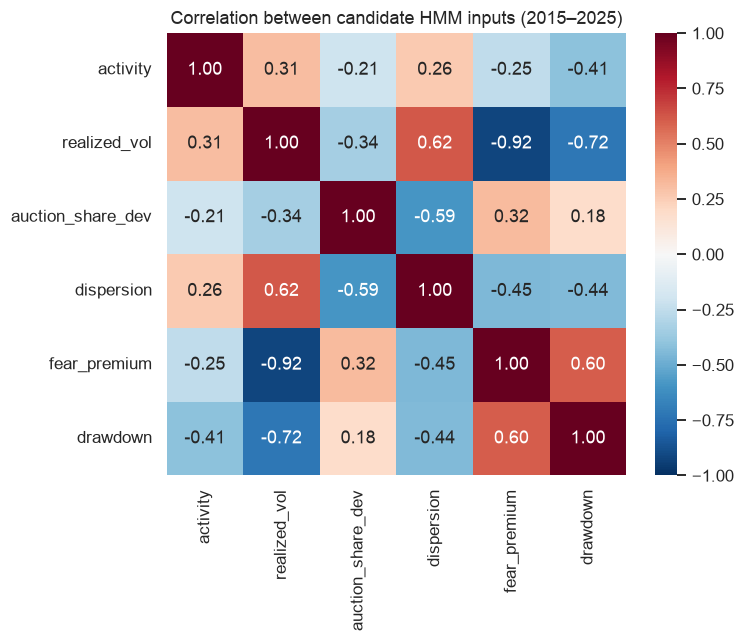

Pairs with |correlation| > 0.8: [('realized_vol', 'fear_premium', np.float64(-0.918))]
Share of 2022–2025 days in each 2015–2021 tercile (about 1/3 each means no drift):


,low,mid,high
activity,0.2473,0.3390,0.4138
realized_vol,0.1336,0.5015,0.3649
auction_share_dev,0.2762,0.3649,0.3589
dispersion,0.0000,0.1635,0.8365
fear_premium,0.2894,0.3917,0.3188
drawdown,0.4148,0.3380,0.2473


In [10]:
corr = X.corr()
corr.to_csv(OUT / "q6_input_correlation.csv")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between candidate HMM inputs (2015–2025)")
plt.tight_layout()
plt.savefig(OUT / "q6_input_correlation.png", bbox_inches="tight")
plt.show()
redundant = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(ru.INPUTS) for b in ru.INPUTS[i + 1:] if abs(corr.loc[a, b]) > 0.8]
print("Pairs with |correlation| > 0.8:", redundant or "none")

# Drift check: does each input's 2022-2025 distribution still span the 2015-2021 terciles?
drift = pd.DataFrame({col: terc.loc["2022":, col].value_counts(normalize=True) for col in ru.INPUTS}).T[["low", "mid", "high"]]
drift.to_csv(OUT / "q6_tercile_shares_2022_2025.csv")
print("Share of 2022–2025 days in each 2015–2021 tercile (about 1/3 each means no drift):")
display(drift)

**Reading Q6.**

- **The fear premium is redundant.** It's about −0.92 correlated with realized volatility, because implied volatility moves much less than realized volatility, so their difference mostly mirrors realized volatility. It also stops on 29 August 2025. Drop it.
- **Dispersion has drifted upward.** Since 2020 it has stayed above most of its 2015–2021 range, so almost no 2022–2025 days fall in its 2015–2021 "low" tercile. An HMM fitted on older years would put most recent days into its high-dispersion state. Either rescale it inside each training window or leave it out.
- The remaining inputs (activity, realized volatility, auction-share deviation, drawdown) are only moderately correlated with each other, except volatility with drawdown (about −0.7).

## Evidence summary

In [11]:
summary = {
    "Q1_median_lag20_autocorrelation_inputs": float(acf.loc[20, ru.INPUTS].median()),
    "Q1_lag1_autocorrelation_model_error": float(acf.loc[1, "model_daily_mean_error"]),
    "Q1_median_spell_length_days": float(sticky["mean spell length (days)"].median()),
    "Q2_mixture_components_with_lowest_bic": int(bic.bic.idxmin()),
    "Q3_largest_tercile_gap_in_slope_on_spike_ratio": float(q3.groupby("input").slope_on_spike_ratio.agg(lambda s: s.max() - s.min()).max()),
    "Q4_max_abs_spearman_slope_vs_inputs": float(link["slope_on_spike_ratio"].abs().max()),
    "Q5_max_bias_range_lgbm": float(spread.bias_range_lgbm.max()),
    "Q5_max_rmse_range_lgbm": float(spread.rmse_range_lgbm.max()),
    "Q5_max_abs_spearman_daily_error_vs_inputs": float(corr_err.abs().max()),
    "Q4_max_abs_spearman_slope_vs_input_changes": float(link_changes["slope_on_spike_ratio"].abs().max()),
    "Q5_oracle_gain_best_single_input": float(bound.iloc[:len(ru.INPUTS)].max_gain.max()),
    "Q5_oracle_gain_core_combination": float(bound.loc[bound.grouping == "core_combination", "max_gain"].iloc[0]),
    "Q5_project_gate_threshold": 0.002,
    "Q6_redundant_pairs": [f"{a}~{b} ({c})" for a, b, c in redundant],
}
with open(OUT / "evidence_summary.json", "w") as handle:
    json.dump(summary, handle, indent=2)
display(summary)

{'Q1_median_lag20_autocorrelation_inputs': 0.4318946954167501,
 'Q1_lag1_autocorrelation_model_error': 0.024237541598817545,
 'Q1_median_spell_length_days': 12.796907018442623,
 'Q2_mixture_components_with_lowest_bic': 5,
 'Q3_largest_tercile_gap_in_slope_on_spike_ratio': 0.05127113287506052,
 'Q4_max_abs_spearman_slope_vs_inputs': 0.5162790697674419,
 'Q5_max_bias_range_lgbm': 0.03272225455952641,
 'Q5_max_rmse_range_lgbm': 0.044876122899723814,
 'Q5_max_abs_spearman_daily_error_vs_inputs': 0.14343543413170412,
 'Q4_max_abs_spearman_slope_vs_input_changes': 0.24569616430081545,
 'Q5_oracle_gain_best_single_input': 0.0005481752572232823,
 'Q5_oracle_gain_core_combination': 0.0010768458932262637,
 'Q5_project_gate_threshold': 0.002,
 'Q6_redundant_pairs': ['realized_vol~fear_premium (-0.918)']}

## Conclusion

| Question | Finding | Supports HMM features? |
|---|---|---|
| Q1 Persistent conditions? | Yes. Inputs stay in a tercile for 5–23 days. | ✅ Regimes exist |
| Q2 Distinct states? | BIC flattens at about 3 components | ✅ Roughly 3 states |
| Q3 Target differs by regime? | Level gaps of about 0.04–0.08 log; spike-ratio slope varies about ±12% | ✅ Modestly |
| Q4 Relationships move with regimes? | The main shift is a decade-long trend; links weaken or flip once trends are removed | ⚠️ Weak |
| Q5 Room left in the best model? | Errors differ in **spread** by regime, but the hindsight ceiling from removing bias is about 0.001 log RMSE | ❌ Not for point accuracy |
| Q6 Usable inputs? | Drop the fear premium (redundant); dispersion drifts | — Inputs pruned |

**Verdict.**
- **Market regimes are real, and auction volume does respond to them.** But the best current model already absorbs most of that through its lag, ratio and market features.
- **As a point-forecast feature, HMM states are unlikely to pass the 0.002 rule.** The level-bias ceiling is about half the threshold even with hindsight. Any gain would have to come from interactions, which this ceiling doesn't cover.
- **The clearer use is uncertainty.** Error spread differs by regime (log RMSE from about 0.44 to 0.48), so regime probabilities are better suited to **prediction intervals** than to lowering RMSE.

**If an HMM is built next, a sensible, cheap design:**
- Inputs: activity, realized volatility, auction-share deviation and drawdown (standardized within each training window). Drop the fear premium; test dispersion only with in-window rescaling.
- Look for about 3 states, choosing the count where BIC flattens.
- Use only filtered probabilities (known at t−1) as features.
- Run the standard ablation with a stop-early rule: if the 2022 fold gains less than 0.001, stop.
- Separately, test whether regime-dependent error spread improves interval calibration.